# Atlas-DeePC on Select-DPC data — results

The read-only dashboard below validates saved rollouts and displays the current results. **It does not rerun the experiment.** Refresh these three dashboard cells to update the display. Experiment configuration and launch controls are further down; do not rerun the launch cell just to view results.

In [1]:
# Read-only dashboard: run independently; never launches simulations.
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/atlas_deepc/benchmarks/atlas_select_data.py").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from atlas_deepc.benchmarks import atlas_select_data as study
RESULT_DIR = Path.home() / "Projects/atlas_select_dpc_data/experiments/reacher/atlas_select_data_p8_k64_r53_dev100_t300_v1"
report = study.report(RESULT_DIR)  # validates every completed trace
rows = report["results"]
df = pd.DataFrame(rows)
print("Validated:", datetime.now(ZoneInfo("America/Chicago")).strftime("%Y-%m-%d %H:%M %Z"))
print("Source:", RESULT_DIR)
if not rows:
    print("No completed rollouts yet.")
else:
    total = report["completed"]
    success = int(report["successes"])
    total_steps = int(df.steps.sum())
    unsolved = int(df.unsolved_steps.sum())
    timing_table = pd.DataFrame(report["timing"]["modules"])
    online = timing_table.set_index("module").loc["Total online control"]
    final_errors_mm = df.mean_last_100.to_numpy()*1000
    cards = [
        ("Rollouts completed", f"{total} / {report['requested']}", "300 control steps per rollout"),
        ("Tracking success", f"{success/total:.0%}", f"{success} successful / {total-success} unsuccessful"),
        ("Median final-window error", f"{np.median(final_errors_mm):.2f} mm", "Median of per-rollout final-100 mean errors"),
        ("Median online time", f"{online['median_ms']:.2f} ms", "Pooled control steps 6–300"),
        ("Unsolved control steps", f"{unsolved:,} / {total_steps:,}", "Solver failures are separate from tracking failures"),
    ]
    html = '<div style="display:flex;flex-wrap:wrap;gap:12px;margin:14px 0">'
    for label, value, note in cards:
        html += (f'<div style="border:1px solid #94a3b8;border-radius:9px;padding:14px;min-width:180px;flex:1">'
                 f'<div style="font-size:13px">{label}</div>'
                 f'<div style="font-size:27px;font-weight:700;margin:8px 0">{value}</div>'
                 f'<div style="font-size:12px">{note}</div></div>')
    display(HTML(html+'</div>'))
    display(Markdown("**Development experiment:** seeds 211–310; original Select-DPC IID data; "
                     "Atlas p=8, K=64, rank 53, no graph guidance. "
                     "These are not held-out 500-seed results."))
    metrics = [
        ("Successful rollouts", f"{success}/{total} ({100*success/total:.1f}%)"),
        ("Median final-100 mean error", f"{np.median(final_errors_mm):.3f} mm"),
        ("90th percentile final-100 mean error", f"{np.percentile(final_errors_mm,90):.3f} mm"),
        ("95th percentile final-100 mean error", f"{np.percentile(final_errors_mm,95):.3f} mm"),
        ("Worst final-100 mean error", f"{final_errors_mm.max():.3f} mm"),
        ("Median full-rollout RMSE", f"{report['median_rollout_rmse_mm']:.3f} mm"),
        ("Median / 95th percentile online time", f"{online['median_ms']:.3f} / {online['p95_ms']:.3f} ms"),
        ("Timing samples", f"{report['timing']['timed_steps']:,} (first 5 steps per seed excluded)"),
    ]
    display(pd.DataFrame(metrics,columns=["Metric","Result"]).style.hide(axis="index"))
    print("Full-rollout RMSE includes the initial reaching transient; final-window error measures settling.")


Validated: 2026-11-09 11:23 CST
Source: /Users/kumiko/Projects/atlas_select_dpc_data/experiments/reacher/atlas_select_data_p8_k64_r53_dev100_t300_v1


**Development experiment:** seeds 211–310; original Select-DPC IID data; Atlas p=8, K=64, rank 53, no graph guidance. These are not held-out 500-seed results.

Metric,Result
Successful rollouts,94/100 (94.0%)
Median final-100 mean error,1.654 mm
90th percentile final-100 mean error,4.457 mm
95th percentile final-100 mean error,15.048 mm
Worst final-100 mean error,328.441 mm
Median full-rollout RMSE,59.487 mm
Median / 95th percentile online time,24.014 / 30.645 ms
Timing samples,"29,500 (first 5 steps per seed excluded)"


Full-rollout RMSE includes the initial reaching transient; final-window error measures settling.


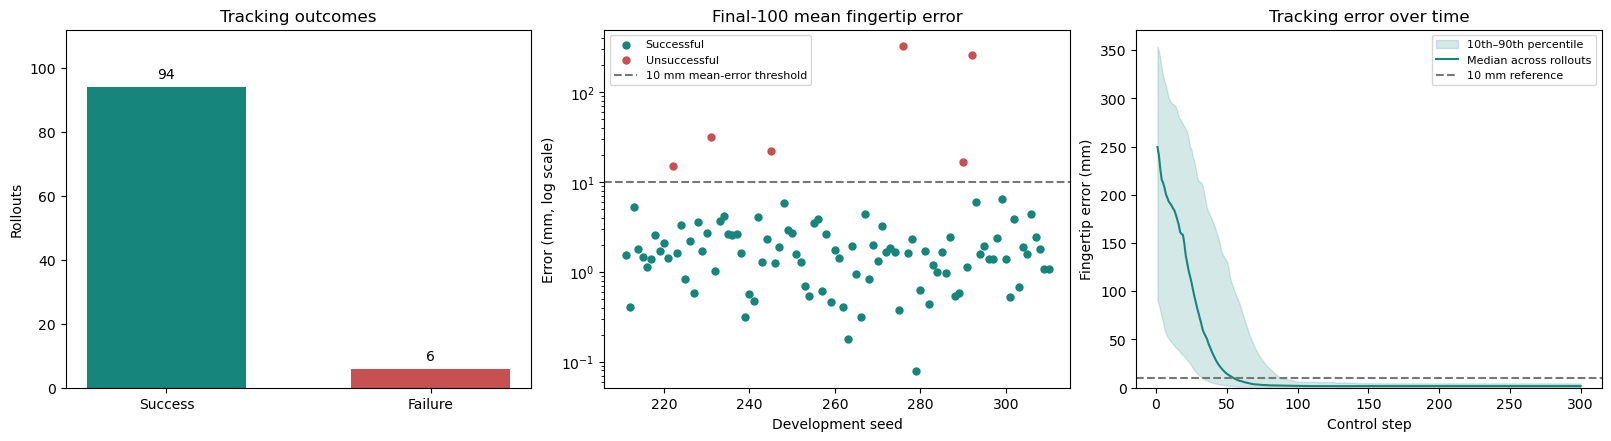

Success is NOT determined by the 10 mm line alone: both final-30 and final-100
windows require mean <10 mm AND maximum <20 mm.


In [2]:
# Read saved errors only. No controller call, fitting, or simulation.
if rows:
    distances = []
    for row in rows:
        with np.load(row["result_path"], allow_pickle=True) as saved:
            distances.append(saved["distance"]*1000)
    distances = np.asarray(distances)
    passed = df.strict_success.to_numpy(dtype=bool)
    fig, axes = plt.subplots(1,3,figsize=(16,4.3),constrained_layout=True)
    colors = ["#16857b", "#c75050"]
    bars = axes[0].bar(["Success","Failure"],[passed.sum(),(~passed).sum()],color=colors,width=.6)
    axes[0].bar_label(bars,padding=4)
    axes[0].set(title="Tracking outcomes",ylabel="Rollouts",ylim=(0,len(rows)*1.12))

    for ok, color, label in [(True,colors[0],"Successful"),(False,colors[1],"Unsuccessful")]:
        axes[1].scatter(df.seed[passed==ok],final_errors_mm[passed==ok],s=25,color=color,label=label)
    axes[1].axhline(10,color="#777777",ls="--",label="10 mm mean-error threshold")
    axes[1].set(yscale="log",title="Final-100 mean fingertip error",xlabel="Development seed",ylabel="Error (mm, log scale)")
    axes[1].legend(fontsize=8)

    steps = np.arange(1,distances.shape[1]+1)
    lo,med,hi = np.percentile(distances,[10,50,90],axis=0)
    axes[2].fill_between(steps,lo,hi,color=colors[0],alpha=.18,label="10th–90th percentile")
    axes[2].plot(steps,med,color=colors[0],label="Median across rollouts")
    axes[2].axhline(10,color="#777777",ls="--",label="10 mm reference")
    axes[2].set(title="Tracking error over time",xlabel="Control step",ylabel="Fingertip error (mm)",ylim=(0,None))
    axes[2].legend(fontsize=8)
    plt.show()
    print("Success is NOT determined by the 10 mm line alone: both final-30 and final-100")
    print("windows require mean <10 mm AND maximum <20 mm.")


In [3]:
if rows:
    failed = df.loc[~df.strict_success].copy()
    display(Markdown("### Unsuccessful rollouts"))
    if failed.empty:
        print("All completed rollouts meet the success criterion.")
    else:
        failure_table = pd.DataFrame({
            "Seed": failed.seed.astype(int),
            "Final-30 mean (mm)": failed.mean_last_30*1000,
            "Final-30 max (mm)": failed.max_last_30*1000,
            "Final-100 mean (mm)": failed.mean_last_100*1000,
            "Final-100 max (mm)": failed.max_last_100*1000,
            "Unsolved steps": failed.unsolved_steps.astype(int),
        })
        display(failure_table.style.hide(axis="index").format({
            k:"{:.2f}" for k in failure_table.columns if "(mm)" in k}))
        if int(failed.unsolved_steps.sum()) == 0:
            print("All failed rollouts had solved control steps: these are tracking failures, not solver failures.")
    display(Markdown("### Online computation breakdown"))
    view = timing_table[timing_table.module.isin([
        "Chart localization","QP construction and solve","Total online control"
    ])][["module","mean_ms","median_ms","p95_ms"]].copy()
    view.columns = ["Component","Mean (ms)","Median (ms)","95th percentile (ms)"]
    display(view.style.hide(axis="index").format({k:"{:.3f}" for k in view.columns[1:]}))
    print("Offline clustering/SVD, environment stepping and file writes are excluded.")
    print("Timings include instrumentation and can be affected by concurrent workloads.")


### Unsuccessful rollouts

Seed,Final-30 mean (mm),Final-30 max (mm),Final-100 mean (mm),Final-100 max (mm),Unsolved steps
222,15.95,28.14,14.96,28.14,0
231,31.47,56.38,32.10,58.94,0
245,22.28,22.28,22.28,22.28,0
276,328.44,328.49,328.44,328.49,0
290,15.52,27.34,16.81,32.04,0
292,261.37,261.37,261.37,261.37,0


All failed rollouts had solved control steps: these are tracking failures, not solver failures.


### Online computation breakdown

Component,Mean (ms),Median (ms),95th percentile (ms)
Chart localization,0.211,0.196,0.258
QP construction and solve,25.159,23.774,30.309
Total online control,25.411,24.014,30.645


Offline clustering/SVD, environment stepping and file writes are excluded.
Timings include instrumentation and can be affected by concurrent workloads.


## Implementation and run settings

A **data-source ablation** of `atlas_deepc.ipynb`: retain **p=8, K=64, rank 53, T_ini=2, T_f=10, T_sim=300**, no graph guidance, and **100 development seeds 211–310**. K and rank are inherited from our-data development tuning, not selected on this dataset; this is not a held-out result.

The authors’ 200 released IID episodes (200 steps each, inputs in `[-0.1,0.1]^2`) replace our `[-1,1]^2` dataset. The pinned Select-DPC checkout is read-only. No Select-DPC controller, historical notebook cells, or data collection is run. We rebuild a new Atlas and SVD bases; existing Atlas/Select-DPC results are never reused or overwritten.

The output order is `[cos(q1), cos(q2), sin(q1), sin(q2), dq1, dq2, fingertip_x, fingertip_y]`. The converter applies the upstream `fix_dataset` transformation (target + fingertip-minus-target), retains post-action input/output alignment, and creates 189 independent L=12 windows per episode: **37,800 columns**. Two redundant sum-angle channels exist only in the storage format and are removed before p=8 clustering/control.

**Reference:** one fixed nearest eligible posture from this original dataset, zero joint velocities, and the exact seeded Cartesian target. The 0.06 m source-target exclusion uses targets actually recorded in the authors’ episodes, not our dataset’s reset seeds. Thus the reference construction rule is unchanged, but the selected posture may differ.

**Unchanged Atlas controller:** Reacher-v5; 12 zero-input warmup steps; raw, unstandardized linear charts; full-window projection selection; Clarabel; Q=diag(5000,5000,5000,5000,20,20,100000,100000), R=0.0001 I, lambda_ini=100000, input limit ±1. No coefficient penalties/boxes, input-increment penalty, graph waypoints, or Select-DPC constraints are added. This is not an otherwise-identical reproduction of Select-DPC, which uses Reacher-v4, a different horizon, initialization, reference, weights, and constraints.

In [ ]:
from pathlib import Path
import os, sys, json, subprocess, signal
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[name] = "1"
os.environ.setdefault("MPLCONFIGDIR", "/tmp/atlas_select_data_mpl")
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "src/atlas_deepc/benchmarks/atlas_select_data.py").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from atlas_deepc.benchmarks import atlas_select_data as study
from comparison_methods.select_dpc import dependency

# Local storage outside the atlas_deepc project; no external drive needed.
# Explicit path also works if this kernel cached the old study.OUTPUT.
RESULT_DIR = Path.home() / "Projects/atlas_select_dpc_data/experiments/reacher/atlas_select_data_p8_k64_r53_dev100_t300_v1"
T_sim = 300
BATCH_SIZE = 100                 # Maximum NEW rollouts in this invocation.
BLOCK_START, BLOCK_STOP = 211, 310  # Next unfinished within this range.
PREPARE_ONLY = False
RUN_EXPERIMENT = True           # Explicit opt-in; Run All is safe by default.
assert T_sim == 300, "Keep this comparison at 300 steps; smoke tests use a separate directory."
assert 211 <= BLOCK_START <= BLOCK_STOP <= 310 and BATCH_SIZE > 0
print("Dataset checkout:", dependency.source_dir())
print("Results:", RESULT_DIR)
print("All original data/results remain unchanged.")
print("Completed:", study.report(RESULT_DIR)["completed"], "/ 100")

## Configuration and provenance

The optional Select-DPC **source checkout** must be installed, but its separate controller environment is not needed. Use the regular Atlas-DeePC Python kernel. The new directory stores source CSV hashes, converted data and recorded episode targets, the refitted Atlas, exact controller bases, per-seed traces, and statistics. A changed source/configuration is rejected on resume; choose a new directory rather than bypassing the manifest.

Only explicit launch writes data. The cells above and the results cells below do not start an experiment.

In [ ]:
cfg = study.config(T_sim)
display(pd.DataFrame([
    ("Dataset", "Select-DPC original IID, 200 × 200 steps"),
    ("Offline columns", "37,800 length-12 windows"),
    ("Output / horizon", "p=8; T_ini=2; T_f=10"),
    ("Atlas", f"K={cfg.clusters}; rank={cfg.svd_rank}; unstandardized"),
    ("Reference", "Fixed p=8 posture from original data; zero velocity; seeded XY target"),
    ("Evaluation", "Seeds 211–310; 300 controlled steps + 12 warmup"),
    ("Q diagonal", [cfg.q_data_goal_joint]*4 + [cfg.q_dq]*2 + [cfg.q_xy]*2),
    ("R / lambda_ini", f"{cfg.r} I / {cfg.lam_ini}"),
    ("Input bound", f"±{cfg.u_limit}"),
    ("Graph guidance", False),
], columns=["Setting", "Value"]))
for name in ("dataset_manifest.json", "progress.json"):
    path = RESULT_DIR / name
    if path.exists():
        saved = json.loads(path.read_text())
        if name == "dataset_manifest.json":
            print("Verified source commit:", saved["signature"]["upstream_commit"])
            print("Derived Hankel SHA256:", saved["hankel_sha256"])
        else:
            print("Latest progress:", saved)

## Run one batch / resume

Set `RUN_EXPERIMENT=True`, then execute the configuration and launch cells. Default `BATCH_SIZE=10` runs the next ten unfinished development seeds and exits. To run up to 100 missing seeds, set `BATCH_SIZE=100`. To request a particular block, set e.g. `BLOCK_START=221, BLOCK_STOP=230`. Completed traces are validated and skipped. All batches share the fixed 100-seed panel; `batch_complete` is not full-panel completion.

Set `PREPARE_ONLY=True` to convert the dataset and fit the Atlas without rollouts. Reset it to `False` for evaluation. Interrupting preserves completed checkpoints; the unfinished seed restarts. Do not edit the runner between batches. Keep the laptop awake. Data and results are stored locally under `~/Projects/atlas_select_dpc_data`, outside the code project; the external drive is not required. For comparable timing, avoid running other experiments concurrently. No full experiment has been run by creating this notebook.

In [ ]:
command = [sys.executable, "-u", "-m", "atlas_deepc.benchmarks.atlas_select_data",
           "--output", str(RESULT_DIR), "--steps", str(T_sim),
           "--batch-size", str(BATCH_SIZE),
           "--block-start", str(BLOCK_START), "--block-stop", str(BLOCK_STOP)]
if PREPARE_ONLY:
    command.append("--prepare-only")
if not RUN_EXPERIMENT:
    print("Not launched. Set RUN_EXPERIMENT=True when ready.")
    print(" ".join(command))
else:
    dependency.verify_source()
    # The runner owns the exclusive run.lock, including offline preparation.
    process = subprocess.Popen(command, cwd=ROOT,
        env=dict(os.environ, PYTHONPATH=str(ROOT / "src")),
        stdin=subprocess.DEVNULL, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, start_new_session=True)
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        if process.wait():
            raise RuntimeError("Run stopped; inspect the error above. Completed traces remain saved.")
    except KeyboardInterrupt:
        if process.poll() is None:
            process.send_signal(signal.SIGINT)
            try:
                process.wait(timeout=20)
            except subprocess.TimeoutExpired:
                print(f"PID {process.pid} is still stopping. Do not start another worker.")
        raise
    finally:
        process.stdout.close()

## Saved results — safe to rerun

Strict success requires **both** final-30 and final-100 windows to have mean fingertip error <10 mm and maximum <20 mm. Error/RMSE use physical fingertip distance, not weighted p=8 tracking cost. Statistics cover completed seeds only. Median online time pools steps 6–300 across completed rollouts, excluding offline clustering/SVD, environment stepping, and disk writes. Concurrent workloads and instrumentation affect timings.

Traces retain the full predicted input/output horizons, g coefficients, slack, history windows, chart-selection residuals, fixed reference, applied inputs, realized outputs, solver statuses, costs, and per-step timings. Smoke-run results, if any, are stored separately and never included here.

In [9]:
# Optional full per-seed table; headline results are at the top.
SHOW_ALL_SEEDS = False
if SHOW_ALL_SEEDS:
    detail_report = study.report(RESULT_DIR)
    detail_df = pd.DataFrame(detail_report["results"])
    if len(detail_df):
        display(pd.DataFrame({
            "Seed": detail_df.seed,
            "Success": detail_df.strict_success,
            "Final-100 mean (mm)": detail_df.mean_last_100*1000,
            "Rollout RMSE (mm)": detail_df.rollout_rmse_mm,
            "Unsolved steps": detail_df.unsolved_steps,
        }).style.hide(axis="index").format({
            "Final-100 mean (mm)":"{:.3f}", "Rollout RMSE (mm)":"{:.3f}"}))
else:
    print("Full 100-row table hidden. Set SHOW_ALL_SEEDS=True if needed.")


Full 100-row table hidden. Set SHOW_ALL_SEEDS=True if needed.


## Inspect one completed rollout

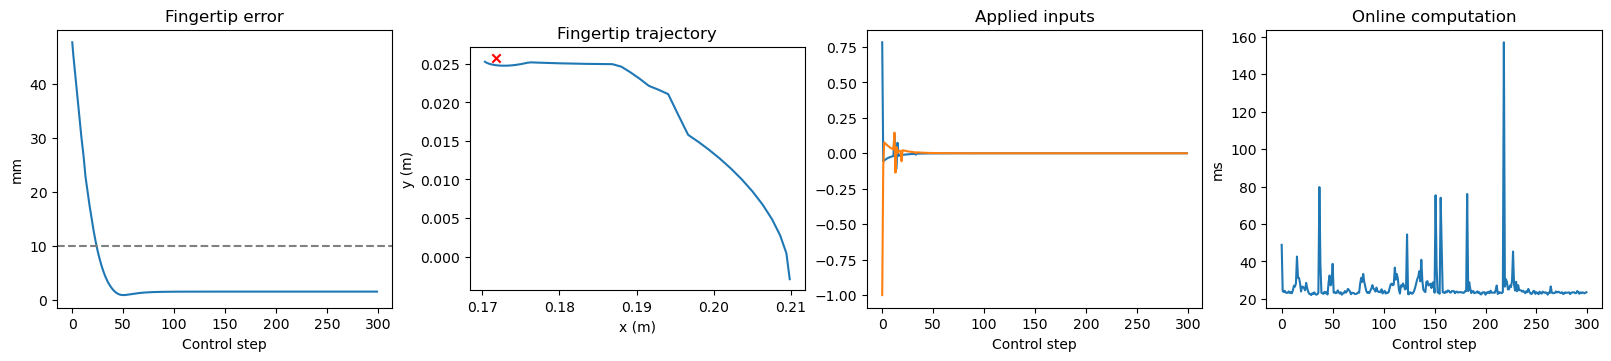

In [10]:
PLOT_SEED = 211
path = RESULT_DIR / f"seed{PLOT_SEED}_control_results.npz"
if path.exists():
    with np.load(path, allow_pickle=True) as a:
        fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), constrained_layout=True)
        axes[0].plot(a["distance"]*1000)
        axes[0].axhline(10, color="grey", ls="--")
        axes[0].set(title="Fingertip error", xlabel="Control step", ylabel="mm")
        axes[1].plot(a["y"][:,6], a["y"][:,7])
        axes[1].scatter(*a["target_xy"], marker="x", c="red")
        axes[1].set(title="Fingertip trajectory", xlabel="x (m)", ylabel="y (m)", aspect="equal")
        axes[2].plot(a["u"])
        axes[2].set(title="Applied inputs", xlabel="Control step")
        axes[3].plot(1000*a["control_compute_time_s"])
        axes[3].set(title="Online computation", xlabel="Control step", ylabel="ms")
        plt.show()
else:
    print(f"Seed {PLOT_SEED} has not completed.")